# Coletando dados brutos

## Configuração de Paths e bibliotecas

In [4]:
import sys
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as img
import random

import urllib.request

import tarfile

In [2]:
# Garante que a raiz do projeto está no sys.path para importar src/
ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

print(f"Raiz do projeto: {ROOT}")

Raiz do projeto: /home/carolina/Documents/Triagem_de_Raio-X


In [3]:
# ── Diretórios ───────────────────────────────────────────────────────
PASTA_RAW_DATA   = Path(ROOT, "data", "raw")
PASTA_RAW_DATA.mkdir(parents=True, exist_ok=True)

PASTA_INPUT_DATA   = Path(ROOT, "data", "input")
PASTA_INPUT_DATA.mkdir(parents=True, exist_ok=True)

print(f"Dados blutos serão salvos em: {PASTA_RAW_DATA}")

Dados blutos serão salvos em: /home/carolina/Documents/Triagem_de_Raio-X/data/raw


## Iniciando Download (teste com um arquivo)

In [ ]:
# URLs for the zip files
# https://nihcc.app.box.com/v/ChestXray-NIHCC
links = [
    'https://nihcc.box.com/shared/static/vfk49d74nhbxq3nqjg0900w5nvkorp5c.gz',
    'https://nihcc.box.com/shared/static/i28rlmbvmfjbl8p2n3ril0pptcmcu9d1.gz',
    'https://nihcc.box.com/shared/static/f1t00wrtdk94satdfb9olcolqx20z2jp.gz',
	'https://nihcc.box.com/shared/static/0aowwzs5lhjrceb3qp67ahp0rd1l1etg.gz',
    'https://nihcc.box.com/shared/static/v5e3goj22zr6h8tzualxfsqlqaygfbsn.gz',
	'https://nihcc.box.com/shared/static/asi7ikud9jwnkrnkj99jnpfkjdes7l6l.gz',
	'https://nihcc.box.com/shared/static/jn1b4mw4n6lnh74ovmcjb8y48h8xj07n.gz',
    'https://nihcc.box.com/shared/static/tvpxmn7qyrgl0w8wfh9kqfjskv6nmm1j.gz',
	'https://nihcc.box.com/shared/static/upyy3ml7qdumlgk2rfcvlb9k6gvqq2pj.gz',
	'https://nihcc.box.com/shared/static/l6nilvfa9cg3s28tqv1qc1olm3gnz54p.gz',
	'https://nihcc.box.com/shared/static/hhq8fkdgvcari67vfhs7ppg2w6ni4jze.gz',
	'https://nihcc.box.com/shared/static/ioqwiy20ihqwyr8pf4c24eazhh281pbu.gz'
]

link = links[0]

In [8]:
LINK = Path(PASTA_RAW_DATA , "images_001.tar.gz")
urllib.request.urlretrieve(link, LINK)

(PosixPath('/home/carolina/Documents/Triagem_de_Raio-X/data/raw/images_001.tar.gz'),
 <http.client.HTTPMessage at 0x7f35d4fed450>)

In [10]:
'https://nihcc.app.box.com/v/ChestXray-NIHCC/file/219760887468'

'https://nihcc.app.box.com/v/ChestXray-NIHCC/file/219760887468'

# descomprimir dados

In [11]:
all_files = os.listdir(PASTA_RAW_DATA)
path_files = [i for i in all_files if i.endswith(".tar.gz")]
print(f"Arquivos pada descomprimir: {path_files}")

Arquivos pada descomprimir: ['images_001.tar.gz']


In [12]:
for i in path_files:
    path = Path(PASTA_RAW_DATA, i)
    file = tarfile.open(path) 
    file.extractall(PASTA_INPUT_DATA) 
    file.close()

/tmp/ipykernel_1417263/3042549780.py:4: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  file.extractall(PASTA_INPUT_DATA)


## Testando dados

In [13]:
data = os.listdir(PASTA_RAW_DATA)
print(f"Dados baixados: {data}")

Dados baixados: ['images_001.tar.gz', 'Data_Entry_2017_v2020.csv']


In [14]:
path_df = [i for i in data if i.endswith(".csv")]
df = pd.read_csv(PASTA_RAW_DATA/path_df[0])
df

,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Sex,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y]
0,00000001_000.png,Cardiomegaly,0,1,57,M,PA,2682,2749,0.143,0.143
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,58,M,PA,2894,2729,0.143,0.143
2,00000001_002.png,Cardiomegaly|Effusion,2,1,58,M,PA,2500,2048,0.168,0.168
3,00000002_000.png,No Finding,0,2,80,M,PA,2500,2048,0.171,0.171
4,00000003_001.png,Hernia,0,3,74,F,PA,2500,2048,0.168,0.168
...,...,...,...,...,...,...,...,...,...,...,...
112115,00030801_001.png,Mass|Pneumonia,1,30801,38,M,PA,2048,2500,0.168,0.168
112116,00030802_000.png,No Finding,0,30802,28,M,PA,2048,2500,0.168,0.168
112117,00030803_000.png,No Finding,0,30803,42,F,PA,2048,2500,0.168,0.168
112118,00030804_000.png,No Finding,0,30804,29,F,PA,2048,2500,0.168,0.168


In [20]:
files = os.listdir(Path(PASTA_INPUT_DATA, "images"))
file = random.choice(files)
path_file = Path(PASTA_INPUT_DATA, "images", file)

In [21]:
diag = df.loc[df['Image Index'] == file, "Finding Labels"]


Ver imagem aleatoria
Nome: 00000031_000.png
Caminho: /home/carolina/Documents/Triagem_de_Raio-X/data/input/images/00000031_000.png
Diagnóstico: 113    No Finding
Name: Finding Labels, dtype: object


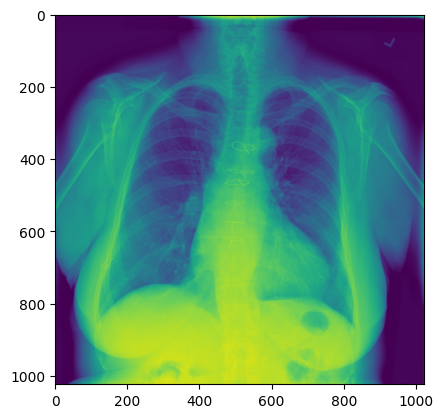

In [22]:
print("Ver imagem aleatoria")
print("Nome:", file)
print("Caminho:", path_file)
print(f"Diagnóstico: {diag}")

im = img.imread(path_file)
plt.imshow(im)


